In [2]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import pandas as pd
import numpy as np
from sksurv.util import Surv
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import (concordance_index_censored, integrated_brier_score)
from sksurv.linear_model import CoxPHSurvivalAnalysis

from functions.preproc import *
from functions.ucphm import *

This dataset is already been treated, only lacking and numerical Na imputer

In [2]:
def univariate_cox_analysis(data_x, data_y, groups, n_splits): 

    univariate_results = []
    event_indicator = [y[0] for y in data_y]
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=12)

    print(f"Starting univariate analysis of {len(data_x.columns)} features...")
    print(f"Using {n_splits}-fold stratified group cross-validation")
    print("-" * 60)

    for i, feature in enumerate(data_x.columns):
        print(f"[{i+1}/{len(data_x.columns)}] Analyzing: {feature}")

        fold_results = {
            "cindex_scores": [],
            "coefficients": [],
            "brier_scores": [],
        }

        for fold, (train_index, test_index) in enumerate(sgkf.split(data_x, event_indicator, groups)):
            try:
                x_train_single = data_x[feature].iloc[train_index].values.reshape(-1, 1)
                x_test_single = data_x[feature].iloc[test_index].values.reshape(-1, 1)

                y_train_surv = [data_y[i] for i in train_index]
                y_test_surv = [data_y[i] for i in test_index]

                event_train = [e for e, t in y_train_surv]
                time_train = [t for e, t in y_train_surv]
                event_test = [e for e, t in y_test_surv]
                time_test = [t for e, t in y_test_surv]

                if np.min(time_test) == np.max(time_test):
                    print(f"    Skipping Brier score: single time point in fold {fold}")
                    continue

                y_train = Surv.from_arrays(event=event_train, time=time_train)
                y_test = Surv.from_arrays(event=event_test, time=time_test)

                cox_model = CoxPHSurvivalAnalysis()
                cox_model.fit(x_train_single, y_train)

                fold_results["coefficients"].append(cox_model.coef_[0])

                risk_scores = cox_model.predict(x_test_single)
                cindex = concordance_index_censored(event_test, time_test, risk_scores)[0]
                fold_results["cindex_scores"].append(cindex)

                surv_funcs = cox_model.predict_survival_function(x_test_single)
                times = np.linspace(
                    max(np.min(time_train), np.min(time_test)) + 1e-6,
                    min(np.max(time_train), np.max(time_test)) - 1e-6,
                    100
                )

                surv_preds = np.asarray([[fn(t) for t in times] for fn in surv_funcs])
                if np.isnan(surv_preds).any():
                    print(f"    Skipping Brier score: NaNs in survival predictions in fold {fold}")
                    continue

                ibs = integrated_brier_score(y_train, y_test, surv_preds, times)
                fold_results["brier_scores"].append(ibs)

            except Exception as e:
                print(f"    Warning: Model fitting failed in fold {fold}: {e}")
                continue

        if fold_results["cindex_scores"]:
            mean_cindex = np.mean(fold_results["cindex_scores"])
            std_cindex = np.std(fold_results["cindex_scores"])

            mean_brier = np.mean(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan
            std_brier = np.std(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan

            mean_coef = np.mean(fold_results["coefficients"])
            std_coef = np.std(fold_results["coefficients"])

            hr = np.exp(mean_coef)
            hr_lower = np.exp(mean_coef - 1.96 * std_coef)
            hr_upper = np.exp(mean_coef + 1.96 * std_coef)

            univariate_results.append({
                "Feature": feature,
                "C_Index_Mean": mean_cindex,
                "C_Index_Std": std_cindex,
                "Integrated_Brier_Score": mean_brier,
                "Brier_Score_Std": std_brier,
                "Coefficient_Mean": mean_coef,
                "Coefficient_Std": std_coef,
                "Hazard_Ratio": hr,
                "HR_95_CI_Lower": hr_lower,
                "HR_95_CI_Upper": hr_upper,
                "N_Successful_Folds": len(fold_results["cindex_scores"]),
            })

            print(f"    C-index: {mean_cindex:.4f} ± {std_cindex:.4f}")
            print(f"    Integrated Brier score: {mean_brier:.4f} ± {std_brier:.4f}")
            print(f"    HR: {hr:.4f} (95% CI: {hr_lower:.4f}–{hr_upper:.4f})")
        else:
            print(f"    Failed to fit any models for {feature}")

    results_df = pd.DataFrame(univariate_results)
    return results_df

In [3]:
dataset = pd.read_csv("data_treated.csv")

In [4]:
categorical_variables = []
with open("categorical.txt", "r") as file:
    for line in file:
        categorical_variables.append(line.strip())

numerical_variables = []
with open("numerical.txt", "r") as file:
    for line in file:
        numerical_variables.append(line.strip())

In [5]:
feature_columns = categorical_variables + numerical_variables

In [6]:
survival_dataset = dataset.drop('Unnamed: 0', axis=1)

In [7]:
data_y = Surv.from_arrays(survival_dataset['Regional LN recurrence'], survival_dataset['Survival days'])
data_x = survival_dataset[feature_columns]
groups = survival_dataset['PERSON_ID']

In [8]:
univariate_results = univariate_cox_analysis(data_x, data_y, groups, 4)
univariate_results

Starting univariate analysis of 42 features...
Using 4-fold stratified group cross-validation
------------------------------------------------------------
[1/42] Analyzing: N (Regional nodes affected)_0.0
    C-index: 0.5977 ± 0.0486
    Integrated Brier score: 0.0684 ± 0.0389
    HR: 0.4957 (95% CI: 0.3944–0.6229)
[2/42] Analyzing: N (Regional nodes affected)_1.0
    C-index: 0.5909 ± 0.0639
    Integrated Brier score: 0.0695 ± 0.0395
    HR: 1.9270 (95% CI: 1.5006–2.4746)
[3/42] Analyzing: N (Regional nodes affected)_2.0
    C-index: 0.4877 ± 0.0054
    Integrated Brier score: 0.0799 ± 0.0468
    HR: 0.0311 (95% CI: 0.0000–46291.0775)
[4/42] Analyzing: N (Regional nodes affected)_3.0
    C-index: 0.4825 ± 0.0226
    Integrated Brier score: 0.0798 ± 0.0469
    HR: 0.0662 (95% CI: 0.0000–73554.8695)
[5/42] Analyzing: Number identifying the lesion in the patient_1
    C-index: 0.5084 ± 0.0224
    Integrated Brier score: 0.0797 ± 0.0469
    HR: 0.7509 (95% CI: 0.6157–0.9157)
[6/42] Analy

c:\Users\marti\anaconda3\envs\survival-env\Lib\site-packages\scipy\linalg\_basic.py:295: RuntimeWarning: invalid value encountered in divide
  x = (b1.T / diag_a).T
c:\Users\marti\anaconda3\envs\survival-env\Lib\site-packages\scipy\linalg\_basic.py:297: RuntimeWarning: invalid value encountered in scalar divide
  rcond = abs_diag_a.min() / abs_diag_a.max()


    C-index: 0.5000 ± 0.0000
    Integrated Brier score: 0.0864 ± 0.0524
    HR: 0.0000 (95% CI: 0.0000–0.0000)
[9/42] Analyzing: Side location of the lesion_L
    C-index: 0.5666 ± 0.0426
    Integrated Brier score: 0.0860 ± 0.0535
    HR: 1.6547 (95% CI: 1.2059–2.2707)
[10/42] Analyzing: Side location of the lesion_R
    C-index: 0.5645 ± 0.0425
    Integrated Brier score: 0.0858 ± 0.0533
    HR: 0.6135 (95% CI: 0.4499–0.8367)
[11/42] Analyzing: Classification with respect to other lesions_1.0
    C-index: 0.5261 ± 0.0439
    Integrated Brier score: 0.0795 ± 0.0470
    HR: 0.7737 (95% CI: 0.5637–1.0619)
[12/42] Analyzing: Classification with respect to other lesions_2.0
    C-index: 0.4440 ± 0.0416
    Integrated Brier score: 0.0799 ± 0.0469
    HR: 0.0225 (95% CI: 0.0000–78941.3603)
[13/42] Analyzing: Classification with respect to other lesions_3.0
    C-index: 0.4674 ± 0.0526
    Integrated Brier score: 0.0797 ± 0.0469
    HR: 1.2244 (95% CI: 0.7902–1.8973)
[14/42] Analyzing: Sour

,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,N_Successful_Folds
0,N (Regional nodes affected)_0.0,0.597718,0.048563,0.068354,0.038868,-0.701816,0.116558,4.956841e-01,3.944475e-01,6.229035e-01,4
1,N (Regional nodes affected)_1.0,0.590877,0.063862,0.069520,0.039521,0.655965,0.127605,1.927001e+00,1.500590e+00,2.474581e+00,4
2,N (Regional nodes affected)_2.0,0.487722,0.005420,0.079881,0.046763,-3.470396,7.251582,3.110471e-02,2.090042e-08,4.629108e+04,4
3,N (Regional nodes affected)_3.0,0.482528,0.022576,0.079807,0.046879,-2.714903,7.102393,6.621139e-02,5.960106e-08,7.355487e+04,4
4,Number identifying the lesion in the patient_1,0.508439,0.022378,0.079658,0.046893,-0.286519,0.101273,7.508729e-01,6.156883e-01,9.157396e-01,4
5,Number identifying the lesion in the patient_2,0.511849,0.021998,0.079628,0.046907,0.377752,0.095212,1.459001e+00,1.210625e+00,1.758335e+00,4
6,Number identifying the lesion in the patient_3,0.503127,0.000861,0.079779,0.046808,-15.009799,0.000635,3.029195e-07,3.025428e-07,3.032967e-07,4
7,Number identifying the lesion in the patient_4,0.500000,0.000000,0.086382,0.052429,-12.001500,0.000033,6.135000e-06,6.134609e-06,6.135391e-06,3
8,Side location of the lesion_L,0.566563,0.042594,0.085980,0.053517,0.503640,0.161453,1.654733e+00,1.205859e+00,2.270699e+00,4
9,Side location of the lesion_R,0.564479,0.042456,0.085775,0.053284,-0.488529,0.158309,6.135282e-01,4.498623e-01,8.367381e-01,4


In [3]:
univariate_results.to_csv('ucphm_diagnostic.csv')

NameError: name 'univariate_results' is not defined

In [4]:
univariate_results = pd.read_csv('ucphm_diagnostic.csv')

In [7]:
univariate_results.sort_values("C_Index_Mean")

,Unnamed: 0,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,N_Successful_Folds
13,13,Source of referral_1,0.441599,0.031794,0.082035,0.044604,-0.042844,0.258302,9.580609e-01,5.774606e-01,1.589512e+00,4
14,14,Source of referral_2,0.441599,0.031794,0.082035,0.044604,0.042844,0.258302,1.043775e+00,6.291238e-01,1.731720e+00,4
33,33,Disease extent_2.0,0.442444,0.044005,0.079923,0.046880,-3.766173,7.715188,2.314045e-02,6.267161e-09,8.544227e+04,4
11,11,Classification with respect to other lesions_2.0,0.444027,0.041635,0.079927,0.046879,-3.796161,7.690113,2.245682e-02,6.388396e-09,7.894136e+04,4
31,31,Disease extent_0.0,0.446076,0.043246,0.079675,0.046885,-0.165270,0.322389,8.476649e-01,4.506105e-01,1.594583e+00,4
39,39,cT_TIs,0.453941,0.045243,0.079884,0.046950,0.369830,0.444181,1.447489e+00,6.060676e-01,3.457080e+00,4
18,18,Istotype at CB_2.0,0.457142,0.014568,0.079907,0.046724,-0.349897,0.544402,7.047608e-01,2.424583e-01,2.048549e+00,4
15,15,Type of invasion at CB_1.0,0.457174,0.047584,0.079818,0.046972,0.512195,0.442709,1.668951e+00,7.008133e-01,3.974522e+00,4
28,28,Her2 overexpression (with immunohystochemistry...,0.462946,0.071532,0.082198,0.053041,-0.199896,0.184845,8.188157e-01,5.699584e-01,1.176330e+00,4
12,12,Classification with respect to other lesions_3.0,0.467428,0.052621,0.079702,0.046874,0.202487,0.223439,1.224444e+00,7.902130e-01,1.897291e+00,4


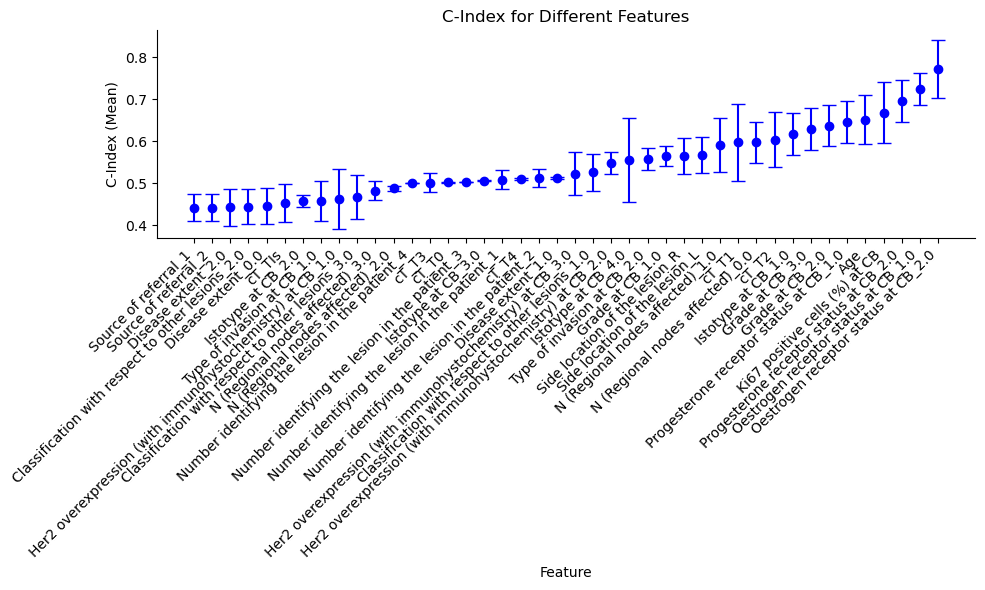

In [11]:
plot_cindex(univariate_results, 'ci_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')

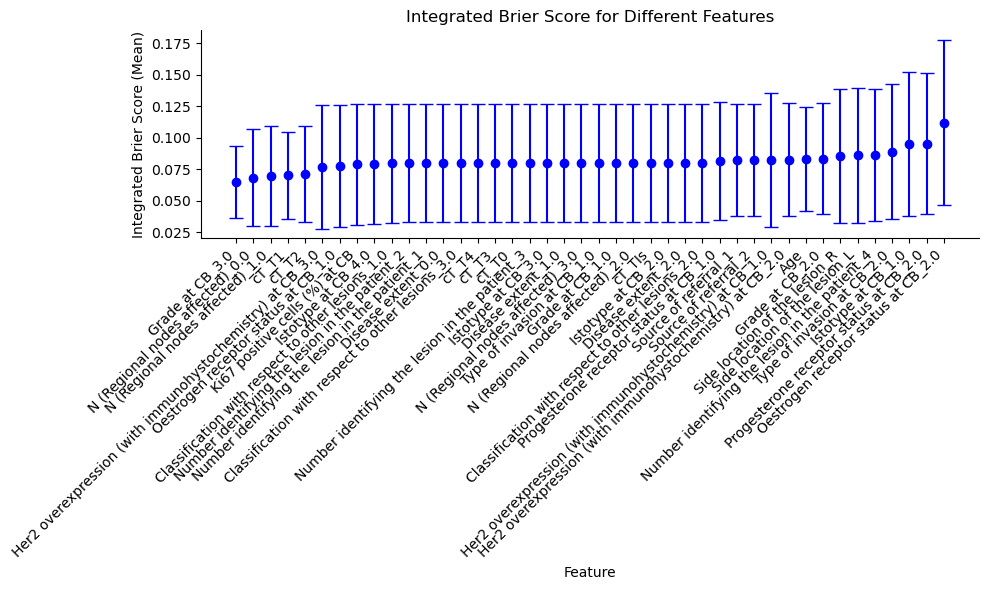

In [5]:
plot_brier(univariate_results, 'brier_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')

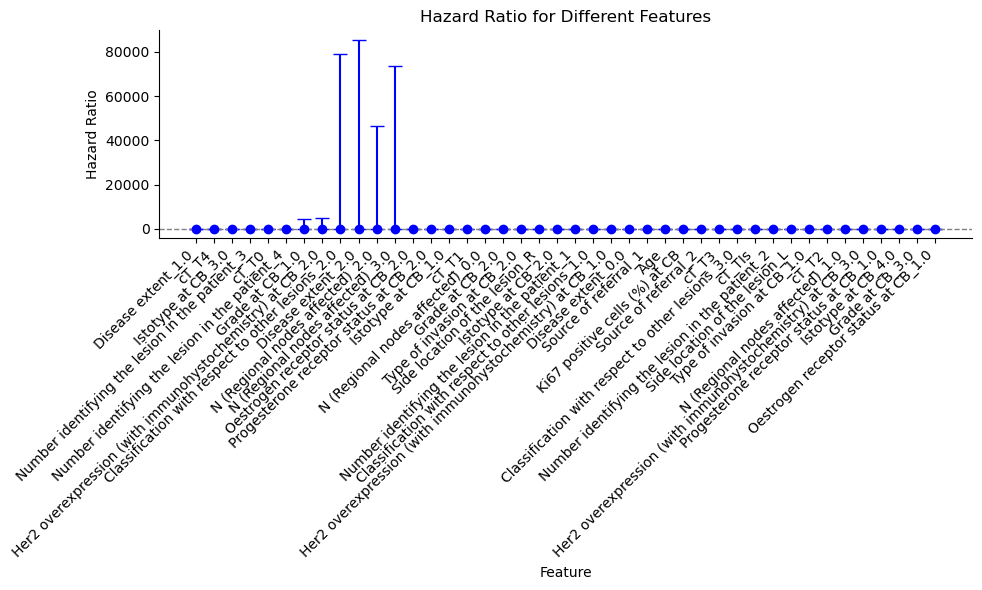

In [6]:
plot_hazard(univariate_results, 'hr_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')